In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")

print("Environment successfully set up!")

Environment successfully set up!


In [10]:
np.random.seed(42)
n_rows = 5000

session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(
    ['desktop', 'mobile', 'tablet'],
    size=n_rows,
    p=[0.5, 0.4, 0.1]
)

session_start_flag = np.ones(n_rows, dtype=int)

add_to_cart_flag = np.random.choice(
    [0, 1],
    size=n_rows,
    p=[0.7, 0.3]
)

purchase_flag = np.where(
    add_to_cart_flag == 1,
    np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]),
    0
)

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)


df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})


df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan


df.to_csv('ga4_sample_session_logs.csv', index=False)

print("Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!")




Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!


In [4]:

total_sessions = df['session_id'].nunique()

sessions_with_cart = df[
    df['add_to_cart_flag'] == 1
]['session_id'].nunique()

sessions_with_purchase = df[
    df['purchase_flag'] == 1
]['session_id'].nunique()

funnel_data = {
    'Funnel Step': [
        '1. Session Start',
        '2. Add to Cart',
        '3. Purchase'
    ],
    'User Sessions': [
        total_sessions,
        sessions_with_cart,
        sessions_with_purchase
    ]
}

funnel_df = pd.DataFrame(funnel_data)

funnel_df['Conversion Rate (%)'] = (
    funnel_df['User Sessions'] / total_sessions
) * 100

print(funnel_df)

        Funnel Step  User Sessions  Conversion Rate (%)
0  1. Session Start           5000                100.0
1    2. Add to Cart           1470                 29.4
2       3. Purchase            905                 18.1


In [5]:
print(df.isnull().sum())

session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64


In [6]:
median_time = df['time_on_site_sec'].median()

df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

df = df.dropna(subset=['session_id'])

# Clean categorical formatting
df['device_category'] = (
    df['device_category']
    .str.lower()
    .str.strip()
)

print(
    "Data cleaning completed. Missing values remaining:",
    df.isnull().sum().sum()
)

Data cleaning completed. Missing values remaining: 0


In [7]:
numeric_cols = [
    'session_start_flag',
    'add_to_cart_flag',
    'purchase_flag',
    'page_views',
    'time_on_site_sec'
]

corr_matrix = df[numeric_cols].corr()

print(corr_matrix)

                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN          1.000000       0.728494   
purchase_flag                      NaN          0.728494       1.000000   
page_views                         NaN         -0.010963      -0.000583   
time_on_site_sec                   NaN          0.001849       0.004230   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag     -0.010963          0.001849  
purchase_flag        -0.000583          0.004230  
page_views            1.000000          0.804072  
time_on_site_sec      0.804072          1.000000  


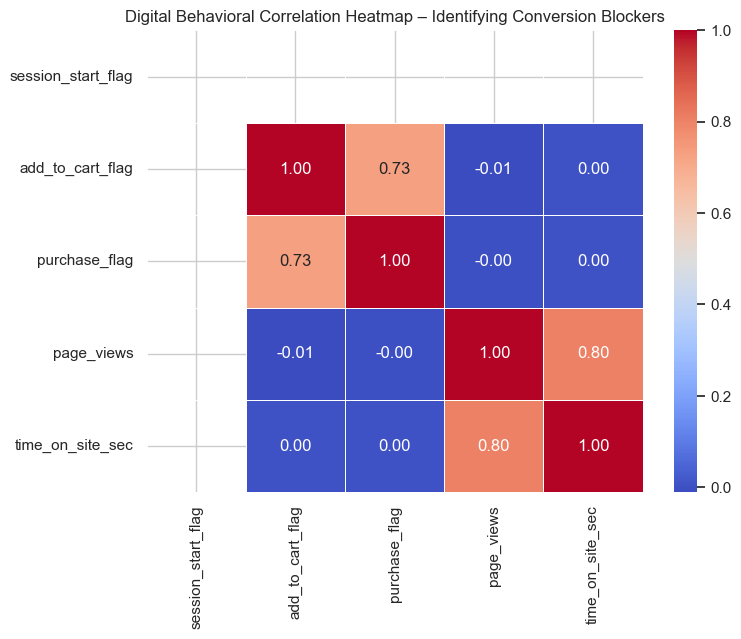

In [8]:
# Plot the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Digital Behavioral Correlation Heatmap – Identifying Conversion Blockers",
    fontsize=12
)

plt.show()